In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

test = pd.read_parquet("../data/test_scores.parquet")
overall = pd.read_csv("../data/overall_lift.csv")
blanket_per_1M = overall.loc[overall.metric == "visits", "incremental_per_1M_users"].iloc[0]

print(test.shape)
print(round(blanket_per_1M))

(902177, 6)
10342


In [2]:
def decile_table(d, score):
    d = d.copy()
    d["decile"] = pd.qcut(
        d[score].rank(method="first", ascending=False), 10, labels=range(1, 11)
    ).astype(int)

    agg = (d.groupby(["decile", "treatment"])
             .agg(n=("visit", "size"), visits=("visit", "sum"), conv=("conversion", "sum"))
             .unstack("treatment"))

    out = pd.DataFrame(index=agg.index)
    out["n_treat"] = agg[("n", 1)]
    out["n_ctrl"] = agg[("n", 0)]
    out["users"] = out.n_treat + out.n_ctrl
    out["visit_rate_treat"] = agg[("visits", 1)] / out.n_treat
    out["visit_rate_ctrl"] = agg[("visits", 0)] / out.n_ctrl
    out["actual_lift"] = out.visit_rate_treat - out.visit_rate_ctrl

    se = np.sqrt(out.visit_rate_treat * (1 - out.visit_rate_treat) / out.n_treat
                 + out.visit_rate_ctrl * (1 - out.visit_rate_ctrl) / out.n_ctrl)
    out["lift_ci_low"] = out.actual_lift - 1.96 * se
    out["lift_ci_high"] = out.actual_lift + 1.96 * se

    out["conv_lift"] = agg[("conv", 1)] / out.n_treat - agg[("conv", 0)] / out.n_ctrl
    out["avg_score"] = d.groupby("decile")[score].mean()
    out["incremental_visits"] = out.actual_lift * out.users
    out["cum_share_targeted"] = out.users.cumsum() / out.users.sum()
    out["cum_share_kept"] = out.incremental_visits.cumsum() / out.incremental_visits.sum()
    return out.reset_index()

up = decile_table(test, "uplift")
rp = decile_table(test, "p_visit")

up[["decile", "users", "actual_lift", "lift_ci_low", "lift_ci_high",
    "avg_score", "cum_share_kept"]].round(4)

,decile,users,actual_lift,lift_ci_low,lift_ci_high,avg_score,cum_share_kept
0,1,90218,0.0552,0.0471,0.0632,0.0687,0.7249
1,2,90218,0.0105,0.0060,0.0149,0.0106,0.8622
2,3,90217,0.0016,-0.0009,0.0041,0.0028,0.8835
3,4,90218,0.0026,0.0011,0.0042,0.0011,0.9182
4,5,90218,0.0005,-0.0004,0.0014,0.0005,0.9248
5,6,90217,0.0002,-0.0006,0.0011,0.0003,0.9281
6,7,90218,0.0010,0.0003,0.0017,0.0001,0.9411
7,8,90217,-0.0002,-0.0010,0.0006,-0.0001,0.9382
8,9,90218,0.0005,-0.0002,0.0012,-0.0002,0.9444
9,10,90218,0.0042,-0.0008,0.0092,-0.0076,1.0000


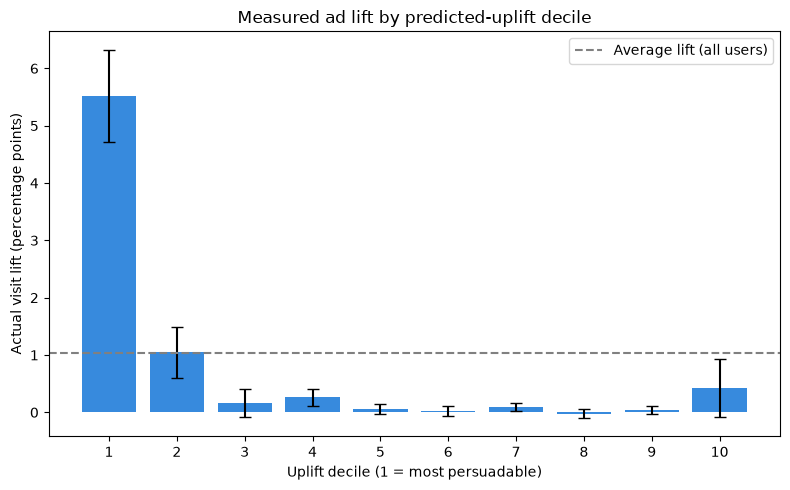

In [3]:
overall_lift = overall.loc[overall.metric == "visits", "abs_lift"].iloc[0]

plt.figure(figsize=(8, 5))
plt.bar(up.decile, up.actual_lift * 100,
        yerr=[(up.actual_lift - up.lift_ci_low) * 100, (up.lift_ci_high - up.actual_lift) * 100],
        capsize=4, color="#378ADD")
plt.axhline(overall_lift * 100, color="gray", linestyle="--", label="Average lift (all users)")
plt.xticks(up.decile)
plt.xlabel("Uplift decile (1 = most persuadable)")
plt.ylabel("Actual visit lift (percentage points)")
plt.title("Measured ad lift by predicted-uplift decile")
plt.legend()
plt.tight_layout()
plt.savefig("../data/lift_by_decile.png", dpi=150)
plt.show()

In [4]:
sc = pd.DataFrame({
    "deciles_targeted": up.decile,
    "share_targeted": up.cum_share_targeted,
    "ad_spend_cut": 1 - up.cum_share_targeted,
    "kept_uplift_model": up.cum_share_kept,
    "kept_response_model": rp.cum_share_kept,
})
sc["cost_per_incr_visit_vs_blanket"] = sc.share_targeted / sc.kept_uplift_model
sc["incr_visits_per_1M_users"] = sc.kept_uplift_model * blanket_per_1M
sc["users_shown_ads_per_1M"] = sc.share_targeted * 1_000_000

sc.round(3)

,deciles_targeted,share_targeted,ad_spend_cut,kept_uplift_model,kept_response_model,cost_per_incr_visit_vs_blanket,incr_visits_per_1M_users,users_shown_ads_per_1M
0,1,0.1,0.9,0.725,0.645,0.138,7497.160,100000.333
1,2,0.2,0.8,0.862,0.890,0.232,8917.250,200000.665
2,3,0.3,0.7,0.883,0.941,0.340,9137.149,299999.889
3,4,0.4,0.6,0.918,0.944,0.436,9496.466,400000.222
4,5,0.5,0.5,0.925,0.970,0.541,9565.076,500000.554
5,6,0.6,0.4,0.928,0.982,0.646,9598.883,599999.778
6,7,0.7,0.3,0.941,0.987,0.744,9732.876,700000.111
7,8,0.8,0.2,0.938,0.995,0.853,9703.601,799999.335
8,9,0.9,0.1,0.944,0.996,0.953,9767.525,899999.667
9,10,1.0,0.0,1.000,1.000,1.000,10342.403,1000000.000


In [5]:
up.to_csv("../data/decile_uplift.csv", index=False)
sc.to_csv("../data/targeting_scenarios.csv", index=False)